In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")
import numpy as np
import mlflow as ml
import _conditions1 as cn
import _sim_iter1 as si
import _loggers1 as lo
import _param1 as prm
import time


import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)




/Users/jacobtiegs/projects/bart_paper/bart_survival_paper_1000/.venv/lib/python3.12/site-packages/arviz/__init__.py:110: MigrationWarning: arviz.InferenceData is no longer available on the arviz package; ArviZ now uses xarray's DataTree for the same role. See the migration guide: https://python.arviz.org/en/latest/user_guide/migration_guide.html#datatree
  warnings.warn(


In [22]:
EXP_NAME = "simple_test_cov"
RUN_NAME = "simple_1"

ITERS = 1
SEED_ADDL=101
N = 1000

PLOT_ALL=True

simple_2_2 = {
    "type": "Simple, 2 group, 50% cens",
    "x_vars": 50, 
    "VAR_CLASS": [2],
    "VAR_PROB":[.5],
    "scale_f": "12 - .5 *x_mat[:,0]",
    "shape_f": "1.2 + 1 *x_mat[:,0]",
    # "cens_scale":5.9
	"cens_scale":1.1
}

# Comp2
SPLIT_RULES2 =  [
    "pmb.ContinuousSplitRule()", # time
    "pmb.ContinuousSplitRule()" # time
]
MODEL_DICT = {"trees": 50,
	"split_rules": SPLIT_RULES2
}
SAMPLER_DICT = {
	"draws": 1000,
	"tune": 100,
	"cores": 4,
	"chains": 4,
	"compute_convergence_checks": False,
    "k":.5,
    "update_fraction":1,
    # "step_size":.1,
    "thin":1
}
import _functions1 as fn
scenario, x_mat, event_dict, sv_true, sv_scale_true = fn.get_sim(np.random.default_rng(99),N, **simple_2_2)
sv_true_mean = sv_true["sv_true"].mean(0)
print(sv_true_mean)
qnt_t = fn.get_quant_times(sv_true_c=sv_true_mean, sv_true= sv_true).flatten()
print(qnt_t)
event_dict = fn.get_quant_events(qnt_t=qnt_t, event=event_dict)
x_tst, x_tst_idx = np.unique(x_mat[:,0], return_index=True)
cens_perc = event_dict["status"][event_dict["status"] == 0].shape[0]/event_dict["status"].shape[0]
print(x_tst)
print(x_tst_idx)
# get uniq times and quantiles as indexes
uniq_t = np.unique(event_dict["t_event"]) 
print(uniq_t)

# qnt_t, qnt_idx = get_quant_times(uniq_t, uniq = False)
true_t = sv_true["true_times"]
true_t


# this could be the source the index minus 1    # singular sv true
sv_true_r0 = sv_true["sv_true"][int(x_tst_idx[0]),:]
sv_true_r0 = sv_true_r0[qnt_t.astype("int") - 1]
sv_true_r1 = sv_true["sv_true"][int(x_tst_idx[1]),:]
sv_true_r1 = sv_true_r1[qnt_t.astype("int") - 1]

print(sv_true_r0)
print(sv_true_r1)

mean shape 1.7319999999999995
mean scale 11.734
mean time draws 11.134683106397231
cens mean 12.865
[0.97440272 0.93732534 0.89225936 0.84048921 0.7832068  0.7217413
 0.65757535 0.59228661 0.52745695 0.46457286 0.404934   0.34958209
 0.29925775 0.25438782 0.21510141 0.18126896 0.15255686 0.12848891
 0.10850712 0.09202555 0.07847334 0.06732523 0.05811988 0.05046759
 0.04404983 0.03861335 0.03396116 0.02994242 0.02644259 0.02337478
 0.02067253 0.01828416 0.01616864 0.01429248 0.01262775 0.01115056
 0.00984016 0.00867828 0.00764872 0.00673702]
[ 3  6  9 14 20]
[0. 1.]
[6 0]
[ 3.  6.  9. 14. 20.]
[0.82740203 0.64708651 0.49259614 0.30023332 0.15787623]
[0.9493143  0.78741506 0.55812398 0.21405757 0.03409676]


In [37]:
import bart_surv_adj as sb
def pb_sb_sub(sv_prob, msk):
    sv_m = sv_prob["sv"][:,msk,:].mean(0)
    sv_q = np.quantile(sv_prob["sv"][:,msk,:], [0.025,0.975], axis=0)    
    return sv_m, sv_q

def get_hdi_ci_2(pb_sv):
    s1 = pb_sv["sv"].shape[0]
    s2 = pb_sv["sv"].shape[1]
    s3 = pb_sv["sv"].shape[2]
    hdi_pre = az.convert_to_dataset(pb_sv["sv"].reshape(1,s1,s2,s3))
    #low-high
    hdi_lh = az.hdi(hdi_pre, prob=.95).x.values
    # low-high
    ci_lh = np.quantile(pb_sv["sv"], [0.025, 0.975], 0)
    return hdi_lh, ci_lh

def get_py_bart_surv2(x_mat, event_dict, model_dict, sampler_dict):
    trn = sb.get_surv_pre_train(y_time = event_dict["t_event"], y_status=event_dict["status"], x = x_mat, weight=None)
    # return trn
    post_test = sb.get_posterior_test(y_status=event_dict["status"], 
                                      y_time=event_dict["t_event"], x=x_mat)
    print(post_test["post_x"].shape)
    # return post_test
    # y_sk = sb.get_y_sklearn(status = event_dict["status"], t_event=event_dict["t_event"])
    # trn = sb.get_surv_pre_train(y_sk = y_sk, x_sk = x_mat, weight=None)
    # post_test = sb.get_posterior_test(y_sk = y_sk, x_test = x_mat)
    small_post_x = np.unique(post_test["post_x"][:,0]).reshape(-1,1)
    xs = np.hstack([np.repeat(0, small_post_x.shape[0]), np.repeat(1, small_post_x.shape[0])])
    small_coords = np.hstack([np.repeat(0, small_post_x.shape[0]), np.repeat(1, small_post_x.shape[0]), ])
    small_post_x = np.vstack([small_post_x, small_post_x])
    small_post_x = np.hstack([small_post_x, xs.reshape(-1,1)])
    # print(small_post_x)
    # print(small_coords)

    # return trn, post_test, small_post_x, small_coords
    BSM = sb.BartSurvModel(model_config=model_dict, sampler_config=sampler_dict)

    # fit with just the time column
    BSM.fit(y=trn["y"], X=trn["x"], weights=trn["w"], coords = trn["coord"], random_seed=99)
    print("DONE")
    # post1 = BSM.sample_posterior_predictive(X_pred=small_post_x, coords=small_coords)
    post1 = BSM.sample_posterior_predictive(post_test["post_x"], coords=post_test["coords"])
    # sv_prob = sb.get_sv_prob(post1, small_coords)
    sv_prob = sb.get_sv_prob(post1, post_test["coords"])
    return sv_prob, BSM

    sv_1 = pb_sb_sub(sv_prob, 0)
    sv_2 = pb_sb_sub(sv_prob, 1)
    uniq_t = BSM.uniq_times
    hdi_lh, ci_lh = get_hdi_ci_2(sv_prob)
    hdi_1 = hdi_lh[0].T
    hdi_2 = hdi_lh[1].T
    
    # del BSM
    # childs = mp.active_children()
    # for child in childs:
    #     child.kill()
    return (sv_1[0], sv_1[1], hdi_1), (sv_2[0], sv_2[1], hdi_2), uniq_t


In [ ]:
SAMPLER_DICT = {
	"draws": 1000,
	"tune": 1000,
	"cores": 4,
	"chains": 4,
	"compute_convergence_checks": False,
    "k":2,
    "use_sparsity" : True,
    # "update_fraction":1,
    # "step_size":.1,
    "thin":5
}

In [152]:
import arviz as az
pb_sv, bsm = get_py_bart_surv2(x_mat=x_mat, event_dict=event_dict, model_dict=MODEL_DICT, sampler_dict=SAMPLER_DICT)

(5000, 51)
k 2
new Model


Multiprocess sampling (4 chains in 4 jobs)
FastSurvMHBART: [trees]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.


DONE
-0.867035917832091
Starting predict layout...
Processing: Dropping 5000 rows down 800 thinned historical forests (Thin factor: 5)...


In [153]:
msk = (x_mat[:,0]==1).flatten()
# pb_sv["sv"][:,msk,:]

print(pb_sv["sv"][:,msk,:].mean(1).mean(0))
print(np.quantile(pb_sv["sv"][:,msk,:].mean(1), [0.025, 0.975],axis=0))

# print(pb_sv["sv"].mean(0)[msk,:].mean(0))
print(pb_sv["sv"][:,~msk,:].mean(1).mean(0))
print(np.quantile(pb_sv["sv"][:,~msk,:].mean(1), [0.025, 0.975],axis=0))



[0.93727485 0.78141404 0.57517107 0.31957135 0.14391277]
[[0.90857175 0.73148517 0.52668386 0.26527544 0.09975432]
 [0.96116699 0.8275038  0.62330509 0.37283298 0.19411808]]
[0.8436521  0.68478286 0.55825882 0.36483658 0.20180433]
[[0.80083459 0.62431136 0.50841181 0.31819314 0.15382876]
 [0.88422779 0.73731101 0.60744334 0.41659666 0.25804849]]


In [154]:
from bart_adj import simple_feature_importance
simple_feature_importance(bsm.idata)

--- Posterior Feature Importance ---
Feature  0: 0.1078  (10.78%)
Feature  1: 0.0469  ( 4.69%)
Feature 23: 0.0361  ( 3.61%)
Feature 20: 0.0334  ( 3.34%)
Feature 49: 0.0271  ( 2.71%)
Feature  4: 0.0261  ( 2.61%)
Feature 24: 0.0217  ( 2.17%)
Feature 30: 0.0208  ( 2.08%)
Feature  5: 0.0205  ( 2.05%)
Feature 16: 0.0197  ( 1.97%)
Feature 12: 0.0196  ( 1.96%)
Feature 35: 0.0195  ( 1.95%)
Feature 46: 0.0193  ( 1.93%)
Feature 36: 0.0191  ( 1.91%)
Feature 13: 0.0190  ( 1.90%)
Feature 29: 0.0185  ( 1.85%)
Feature 37: 0.0185  ( 1.85%)
Feature 44: 0.0184  ( 1.84%)
Feature 48: 0.0181  ( 1.81%)
Feature 41: 0.0181  ( 1.81%)
Feature  9: 0.0180  ( 1.80%)
Feature 18: 0.0178  ( 1.78%)
Feature 38: 0.0177  ( 1.77%)
Feature 22: 0.0176  ( 1.76%)
Feature 11: 0.0176  ( 1.76%)
Feature 31: 0.0173  ( 1.73%)
Feature 39: 0.0166  ( 1.66%)
Feature 33: 0.0164  ( 1.64%)
Feature 50: 0.0162  ( 1.62%)
Feature  7: 0.0160  ( 1.60%)
Feature  8: 0.0156  ( 1.56%)
Feature 32: 0.0156  ( 1.56%)
Feature 14: 0.0154  ( 1.54%)
Featur

In [146]:
np.nanmax(bsm.idata.sample_stats["node_counts"].values)
np.unique(bsm.idata.sample_stats["node_counts"].values, return_counts=True)


(array([ 5.,  7.,  9., 11., 13., 15., nan], dtype=float32),
 array([  28207,  106674,   47295,    9475,    7608,     741, 9800000]))

(array([ 1.,  0.,  2.,  0.,  0.,  0.,  0.,  0.,  4.,  1.,  2.,  0.,  2.,
         0.,  4.,  6.,  6.,  4.,  8.,  8., 10.,  9., 11., 14., 13., 16.,
        12., 18., 16., 20., 18., 14., 23., 13., 25., 13., 26., 21., 20.,
        21., 25., 29., 14., 29., 21., 18., 18., 18., 17., 14., 14., 20.,
         7., 11., 15., 12., 17., 10.,  7., 10.,  7.,  9.,  7.,  9.,  6.,
         4., 12.,  4.,  3.,  7.,  4.,  1.,  2.,  3.,  3.,  2.,  0.,  2.,
         1.,  0.,  0.,  1.,  2.,  0.,  0.,  1.,  1.,  0.,  1.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([0.10845607, 0.1098675 , 0.11127893, 0.11269036, 0.1141018 ,
        0.11551323, 0.11692466, 0.11833609, 0.11974752, 0.12115895,
        0.12257039, 0.12398182, 0.12539325, 0.12680468, 0.12821611,
        0.12962754, 0.13103898, 0.13245041, 0.13386184, 0.13527327,
        0.1366847 , 0.13809613, 0.13950757, 0.140919  , 0.14233043,
        0.14374186, 0.14515329, 0.14656473, 0.14797616, 0.14938759,
        0.15079902, 0.1522

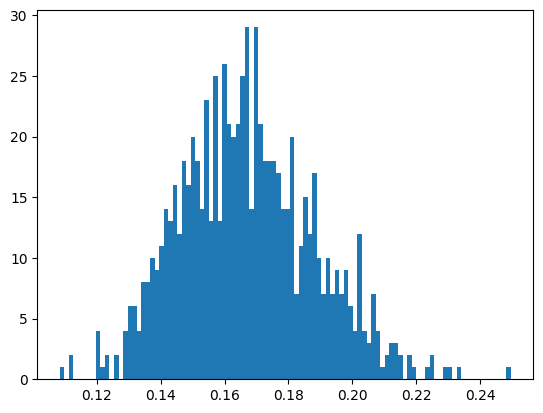

In [147]:
import matplotlib.pyplot as plt
plt.hist(pb_sv["sv"].mean(1)[:,4], bins=100)


In [140]:
import subprocess
import pandas as pd
def save_to_csv(event_dict, x_mat, file="exp1_tmp.csv"):
    """helper function that passes the simulated event dataset to a csv
    - Used for R-bart

    Args:
        event_dict (_type_): _description_
        x_mat (_type_): _description_
        file (str, optional): _description_. Defaults to "exp1_tmp.csv".
    """
    col = ["t","s"] + ["x"+str(i) for i in range(x_mat.shape[1])]
    df = pd.DataFrame(np.hstack(
        [
            event_dict["t_event"],
            event_dict["status"],
            x_mat
        ]
    ),columns= col)
    exp_name = file
    path = f"../data/{exp_name}"
    with open(path, 'w') as f:
        df.to_csv(f, index=False)
    # df.to_csv(path,index = False)

def get_r_bart2(event_dict, x_mat):
    save_to_csv(event_dict, x_mat, file="exp2_tmp.csv")
    # subprocess.call("/usr/bin/Rscript --vanilla ../R/bart_2.R", shell=True)
    subprocess.call("/usr/local/bin/Rscript --vanilla ../R/bart_2.R", shell=True)
    with open("../data/exp2_tmp_out2.csv","r") as f:
        r_sv = pd.read_csv(f).values
    return(r_sv)
    # r_sv = pd.read_csv("../data/exp2_tmp_out2.csv").values
    msk = r_sv[:,0]==0
    r_sv_m1 = r_sv[msk,1].T
    r_sv_m2 = r_sv[~msk,1].T
    r_sv_q1 = r_sv[msk,2:].T
    r_sv_q2 = r_sv[~msk,2:].T
    return (r_sv_m1, r_sv_q1), (r_sv_m2, r_sv_q2)
    

In [141]:
rp = get_r_bart2(event_dict, x_mat)

Loading required package: nlme
Loading required package: survival

Attaching package: ‘dplyr’

The following object is masked from ‘package:nlme’:

    collapse

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



*****Calling gbart: type=2
*****Data:
data:n,p,np: 2472, 51, 10000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 3.000000, 0.644343
xp1,xp[np*p]: 3.000000, 0.644343
*****Number of Trees: 50
*****Number of Cut Points: 4 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-0.867036
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,51,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 1000 (out of 1920)
done 1100 (out of 1920)
done 1200 (out of 1920)
done 1300 (out of 1920)
done 1400 (out of 1920)
done 1500 (out of 1920)
done 1600 (out of 1920)
done 1700 (out of 1920)
done 1800 (out of 1920)
done 1900 (out of 1920)
time: 7s
trcnt,tecnt: 167,167


In [142]:
np.transpose(rp)

array([[0.95191541, 0.78190703, 0.56981266, 0.31036983, 0.13794088],
       [0.92743126, 0.73570406, 0.52061865, 0.25809339, 0.09283179],
       [0.96898044, 0.82397325, 0.62235725, 0.36484051, 0.19246425],
       [0.82736464, 0.68655191, 0.55804347, 0.37660531, 0.21473153],
       [0.7959067 , 0.63865079, 0.50726534, 0.32318076, 0.15950041],
       [0.85837116, 0.73244654, 0.60718905, 0.43367199, 0.27034207]])

In [135]:
print(sv_true_r1)
print(sv_true_r0)


[0.9493143  0.78741506 0.55812398 0.21405757 0.03409676]
[0.82740203 0.64708651 0.49259614 0.30023332 0.15787623]


[0.93635526 0.77997538 0.5742529  0.31812052 0.14009518]
[[0.8897066  0.72969313 0.52483898 0.25589024 0.08844111]
 [0.96592497 0.8341701  0.6271668  0.3909313  0.20670391]]
[0.84246261 0.68714978 0.5548549  0.36498616 0.19763869]
[[0.79678019 0.62480246 0.50238107 0.29825437 0.13766709]
 [0.8891603  0.74008951 0.60821519 0.42492381 0.27063478]]
